# 02. Time-Series Feature Engineering & Chronological Splitting
**Project:** Air Quality Forecasting via Gradient Boosting and LSTM Models (Phase 1: Traditional ML Foundation)  
**Author:** Ajit (Time-Series Feature Engineering Engineer)  
**Dataset:** UCI Beijing Multi-Site Air Quality Dataset (Benchmark Station: Aotizhongxin & 12 Stations Architecture)  
**Forecasting Task:** Predict hourly PM2.5 concentration at time $t + 1$ hour ($PM2.5_{t+1}$) using strictly observations available at time $t$ and earlier ($X_t ightarrow y_{t+1}$).

---

## Notebook Structure
1. **Environment Setup & Imports**
2. **Data Ingestion & Causal Preprocessing Pipeline** (`src.data.load_data`, `src.preprocessing`)
3. **Supervised Target Construction ($t + 1$ hour) & Anti-Leakage Audit**
4. **Autoregressive & Multi-Pollutant Lag Feature Engineering**
5. **Causal Historical Rolling Statistics (Mean & Standard Deviation)**
6. **Temporal, Cyclical & Domain Meteorological Features**
7. **Comprehensive Feature Pipeline Execution (`src.features.generate_features`)**
8. **Feature Importance & Correlation Diagnostics with $y_{t+1}$**
9. **Strict Chronological Train / Validation / Test Splitting (`src.split_data`)**
10. **Leak-Free Transformation Pipeline (`StandardScaler` on Train Only)**
11. **Final Feature Matrix Extraction & Interface Handoff for Modeling**


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load_data import load_station_data, load_all_stations
from src.preprocessing import clean_features
from src.features import (
    create_target,
    create_lag_features,
    create_rolling_features,
    create_calendar_features,
    create_cyclical_features,
    create_domain_weather_features,
    generate_features,
    extract_feature_matrix,
    get_feature_dictionary,
)
from src.split_data import (
    chronological_split,
    get_split_boundaries,
    validate_split_leakage,
    fit_transform_scaler,
)

# Styling
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120

print("Feature engineering environment initialized successfully.")


Feature engineering environment initialized successfully.


---
## 1. Data Ingestion & Causal Preprocessing

We ingest the primary benchmark station **Aotizhongxin** and apply Saksham's causal preprocessing pipeline (`src.preprocessing.clean_features`).  
Core safety rule: The ground-truth target $PM2.5$ is **never imputed**. Missing targets remain `NaN` and are tracked via `target_valid`.


In [2]:
raw_data_path = PROJECT_ROOT / "data/raw/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
df_raw = load_station_data(raw_data_path)
print(f"Loaded {df_raw['station'].iloc[0]} dataset: {len(df_raw):,} records from {df_raw['datetime'].min()} to {df_raw['datetime'].max()}")

# Apply causal feature cleaning
df_clean, cleaning_report = clean_features(df_raw, max_ffill_hours=6, encode_wind=True)
print(f"Cleaning complete: {cleaning_report['final_rows']:,} rows preserved (0 dropped).")
print(f"Target missing count: {cleaning_report['target_missing_count']:,} ({cleaning_report['target_missing_count']/len(df_clean)*100:.2f}%)")


Loaded Aotizhongxin dataset: 35,064 records from 2013-03-01 00:00:00 to 2017-02-28 23:00:00
Cleaning complete: 35,064 rows preserved (0 dropped).
Target missing count: 925 (2.64%)


---
## 2. Supervised Target Construction ($t + 1$ Hour)

**Forecasting Definition:**
For each record at timestamp $t$, the forecast target is the PM2.5 measurement at timestamp $t + 1$ hour:
$$y_t = PM2.5_{t+1}$$

**Anti-Leakage Safeguard:**
We strictly do NOT blindly shift rows. If an hourly timestamp is missing or a station boundary is encountered, the target is assigned `NaN`.


In [3]:
df_targeted = create_target(df_clean, target_col="PM2.5", horizon=1, new_target_col="target_pm25")

# Inspect target shift
preview_cols = ["datetime", "station", "PM2.5", "target_pm25"]
print("Preview of Supervised Target Formulation (First 5 Rows):")
display(df_targeted[preview_cols].head())

print("\nPreview of Boundary Row (Last 3 Rows):")
display(df_targeted[preview_cols].tail(3))


Preview of Supervised Target Formulation (First 5 Rows):


,datetime,station,PM2.5,target_pm25
0,2013-03-01 00:00:00,Aotizhongxin,4.0,8.0
1,2013-03-01 01:00:00,Aotizhongxin,8.0,7.0
2,2013-03-01 02:00:00,Aotizhongxin,7.0,6.0
3,2013-03-01 03:00:00,Aotizhongxin,6.0,3.0
4,2013-03-01 04:00:00,Aotizhongxin,3.0,5.0



Preview of Boundary Row (Last 3 Rows):


,datetime,station,PM2.5,target_pm25
35061,2017-02-28 21:00:00,Aotizhongxin,16.0,21.0
35062,2017-02-28 22:00:00,Aotizhongxin,21.0,19.0
35063,2017-02-28 23:00:00,Aotizhongxin,19.0,NaN


---
## 3. Modular Feature Engineering

We create candidate feature sets grounded in atmospheric chemistry and physical transport:
1. **Autoregressive PM2.5 Lags:** Captures persistence and memory at 1h, 2h, 3h, 6h, 12h, and 24h.
2. **Multi-Pollutant Lags (PM10, NO2, CO):** Traces precursor emissions, traffic dynamics, and combustion plumes.
3. **Causal Historical Rolling Statistics:** Computes backward-looking rolling means and standard deviations over 3h, 6h, 12h, and 24h. Excludes the future target.
4. **Temporal & Cyclical Encodings:** Models diurnal and seasonal periodicity via $\sin$ and $\cos$.
5. **Domain Weather Interactions:** Computes dew point depression (proxy for relative humidity / aerosol growth) and wind stagnation ($WSPM < 1.5$ m/s).


In [4]:
# 1. Autoregressive PM2.5 lags
df_demo, lag_names = create_lag_features(df_clean, columns=["PM2.5"], lags=[1, 2, 3, 6, 12, 24])

# 2. Causal rolling statistics
df_demo, roll_names = create_rolling_features(df_demo, columns=["PM2.5"], windows=[3, 6, 12, 24], stats=["mean", "std"])

# 3. Calendar & Cyclical features
df_demo, cal_names = create_calendar_features(df_demo)
df_demo, cyc_names = create_cyclical_features(df_demo)

# 4. Domain weather interactions
df_demo, dom_names = create_domain_weather_features(df_demo)

print(f"Generated {len(lag_names)} lag features, {len(roll_names)} rolling features, {len(cal_names)} calendar, {len(cyc_names)} cyclical, {len(dom_names)} domain weather features.")


Generated 6 lag features, 8 rolling features, 5 calendar, 6 cyclical, 3 domain weather features.


---
## 4. End-to-End Feature Generation Pipeline

Using `generate_features`, we execute the unified, leakage-safe pipeline across all candidate features.


In [5]:
df_features, feature_cols, metadata = generate_features(
    df=df_clean,
    target_col="PM2.5",
    horizon=1,
    pm25_lags=[1, 2, 3, 6, 12, 24],
    pollutant_lags={"PM10": [1, 3, 6, 24], "NO2": [1, 3, 6, 24], "CO": [1, 3, 6, 24]},
    rolling_windows=[3, 6, 12, 24],
    rolling_stats=["mean", "std"],
    rolling_cols=["PM2.5", "PM10", "TEMP"],
    include_calendar=True,
    include_cyclical=True,
    include_domain_weather=True,
    include_wind_encoding=True,
    new_target_col="target_pm25",
)

print(f"Total records: {metadata['total_records']:,}")
print(f"Candidate feature count: {metadata['num_features']}")
print(f"Valid target records: {metadata['valid_target_records']:,} ({metadata['valid_target_records']/metadata['total_records']*100:.2f}%)")
print(f"Missing target records: {metadata['missing_target_records']:,}")


Total records: 35,064
Candidate feature count: 70
Valid target records: 34,138 (97.36%)
Missing target records: 926


---
## 5. Feature Dictionary & Physical Interpretation

Every engineered feature is documented with its formula, physical justification, and candidate modeling role.


In [6]:
feat_dict = get_feature_dictionary()
print(f"Feature Dictionary contains {len(feat_dict)} documented variables across {feat_dict['feature_group'].nunique()} groups:")
display(feat_dict.groupby("feature_group")["feature_name"].count().to_frame("Count"))

print("\nSample Feature Definitions:")
display(feat_dict.head(10))


Feature Dictionary contains 59 documented variables across 10 groups:


,Count
feature_group,
Autoregressive Lags,6
Base Measurements,6
Base Meteorology,5
Cyclical Encodings,6
Domain Weather,3
Multi-Pollutant Lags,12
Rolling Statistics,12
Target,1
Temporal Features,5



Sample Feature Definitions:


,feature_group,feature_name,formula,physical_meaning,role
0,Target,target_pm25,PM2.5_{t+1},Ground truth PM2.5 concentration 1 hour ahead,Supervised Target Label
1,Base Measurements,PM2.5,PM2.5_t,Contemporaneous PM2.5 at time t (1h before tar...,Primary Autoregressive Feature
2,Base Measurements,PM10,PM10_t,Contemporaneous coarse particulate matter,Predictive Feature (r=0.88 with PM2.5)
3,Base Measurements,SO2,SO2_t,Sulfur dioxide; coal combustion indicator,Emissions Feature (r=0.48 with PM2.5)
4,Base Measurements,NO2,NO2_t,Nitrogen dioxide; traffic and combustion tracer,Emissions Feature (r=0.66 with PM2.5)
5,Base Measurements,CO,CO_t,Carbon monoxide; incomplete combustion tracer,Emissions Feature (r=0.78 with PM2.5)
6,Base Measurements,O3,O3_t,Ground-level ozone; photochemical oxidant,Secondary Chemistry Feature
7,Base Meteorology,TEMP,TEMP_t,Surface dry-bulb temperature (°C),Atmospheric boundary layer proxy
8,Base Meteorology,PRES,PRES_t,Surface barometric pressure (hPa),Synoptic weather front tracker
9,Base Meteorology,DEWP,DEWP_t,Dew point temperature (°C),Absolute atmospheric moisture proxy


---
## 6. Target Correlation & Autoregressive Memory

We evaluate linear and rank correlations between our candidate features and the 1-hour ahead target $y_{t+1}$.


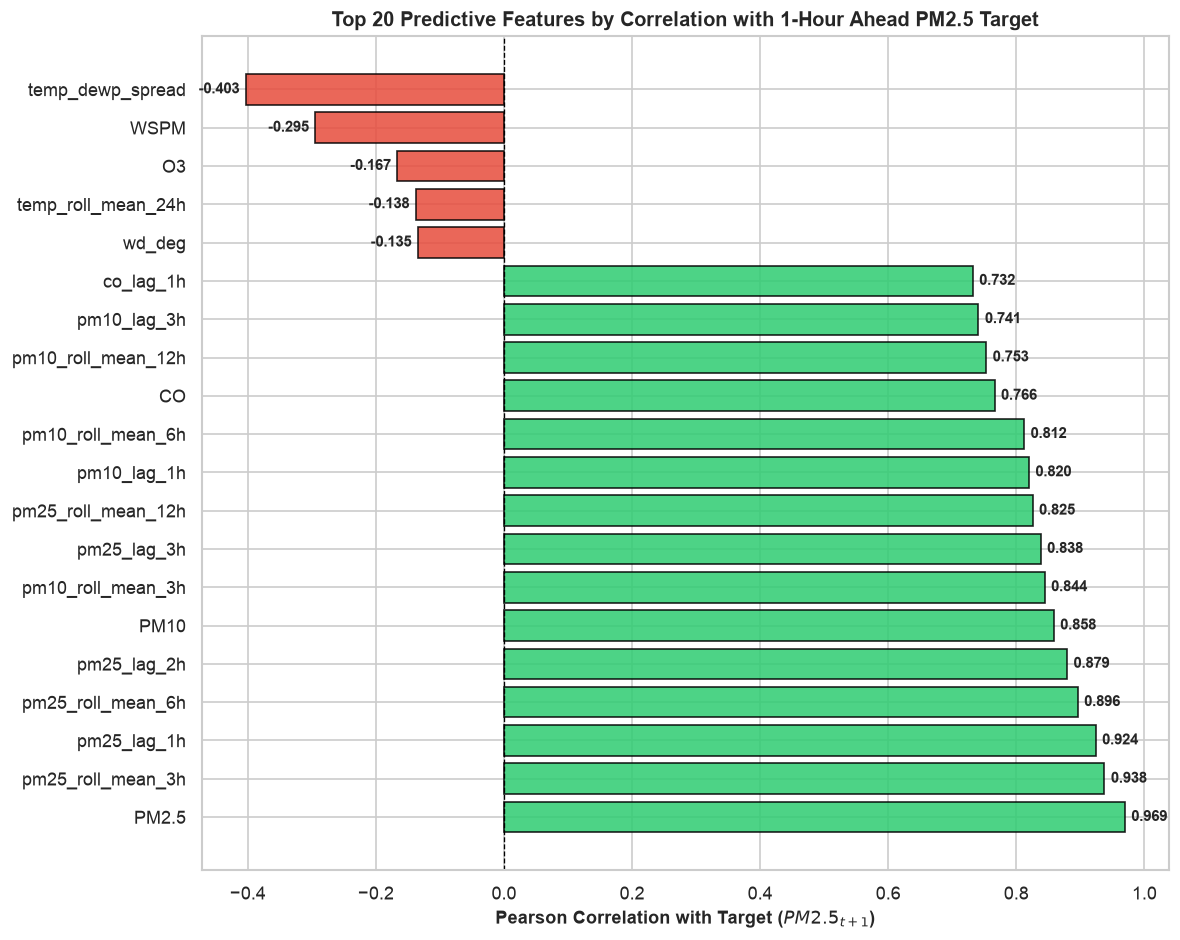

Top 10 Most Correlated Features with 1-Hour Ahead PM2.5:


,Correlation
PM2.5,0.969436
pm25_roll_mean_3h,0.937538
pm25_lag_1h,0.923869
pm25_roll_mean_6h,0.895855
pm25_lag_2h,0.879196
PM10,0.858390
pm10_roll_mean_3h,0.844246
pm25_lag_3h,0.837963
pm25_roll_mean_12h,0.825333
pm10_lag_1h,0.819697


In [7]:
# Compute Pearson correlations with target_pm25
corr_series = df_features[feature_cols + ["target_pm25"]].corr()["target_pm25"].drop("target_pm25").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top_pos = corr_series.head(15)
top_neg = corr_series.tail(5)
top_corr = pd.concat([top_pos, top_neg])

colors = ["#2ecc71" if val > 0 else "#e74c3c" for val in top_corr.values]
bars = ax.barh(top_corr.index, top_corr.values, color=colors, edgecolor="black", alpha=0.85)
ax.set_xlabel("Pearson Correlation with Target ($PM2.5_{t+1}$)", fontsize=11, fontweight="bold")
ax.set_title("Top 20 Predictive Features by Correlation with 1-Hour Ahead PM2.5 Target", fontsize=12, fontweight="bold")
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

for bar in bars:
    w = bar.get_width()
    ha = "left" if w >= 0 else "right"
    ax.text(w + (0.01 if w >= 0 else -0.01), bar.get_y() + bar.get_height()/2.0, f"{w:.3f}", ha=ha, va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

print("Top 10 Most Correlated Features with 1-Hour Ahead PM2.5:")
display(top_pos.to_frame("Correlation"))


---
## 7. Strict Chronological Train / Validation / Test Splitting

We partition the time series in strictly forward chronological order:
- **Training (70%):** Model parameter learning.
- **Validation (15%):** Hyperparameter tuning, feature selection, and early stopping.
- **Testing (15%):** Untouched final hold-out evaluation.

Random shuffling is strictly prohibited.


In [8]:
train_df, val_df, test_df, split_report = chronological_split(
    df=df_features,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    embargo_hours=0,
)

print("="*60)
print("CHRONOLOGICAL SPLIT SUMMARY (Aotizhongxin Benchmark Station)")
print("="*60)
print(f"Train Partition : {split_report['train_records']:,} rows ({split_report['train_percentage']}%) | {split_report['train_start']} to {split_report['train_end']}")
print(f"Val Partition   : {split_report['val_records']:,} rows ({split_report['val_percentage']}%) | {split_report['val_start']} to {split_report['val_end']}")
print(f"Test Partition  : {split_report['test_records']:,} rows ({split_report['test_percentage']}%) | {split_report['test_start']} to {split_report['test_end']}")
print(f"Total Records   : {split_report['total_records']:,} rows (100.0%)")
print("="*60)


CHRONOLOGICAL SPLIT SUMMARY (Aotizhongxin Benchmark Station)
Train Partition : 24,544 rows (70.0%) | 2013-03-01 00:00:00 to 2015-12-18 15:00:00
Val Partition   : 5,260 rows (15.0%) | 2015-12-18 16:00:00 to 2016-07-24 19:00:00
Test Partition  : 5,260 rows (15.0%) | 2016-07-24 20:00:00 to 2017-02-28 23:00:00
Total Records   : 35,064 rows (100.0%)


---
## 8. Anti-Leakage Split Validation

We execute `validate_split_leakage` to audit monotonicity, zero overlap, and target lookahead boundary constraints.


In [9]:
audit = validate_split_leakage(train_df, val_df, test_df, horizon_hours=1)
print(f"Chronological Monotonicity : {'PASS' if audit['is_chronological'] else 'FAIL'}")
print(f"Zero Timestamp Overlap    : {'PASS' if audit['zero_timestamp_overlap'] else 'FAIL'}")
print(f"Train Target Leaks into Val : {audit['train_target_leaks_into_val']}")
print(f"Val Target Leaks into Test  : {audit['val_target_leaks_into_test']}")
print(f"All Anti-Leakage Checks     : {'PASSED' if audit['passed_all_checks'] else 'FLAGGED'}")


Chronological Monotonicity : PASS
Zero Timestamp Overlap    : PASS
Train Target Leaks into Val : False
Val Target Leaks into Test  : False
All Anti-Leakage Checks     : PASSED


---
## 9. Leak-Free Learned Scaling (`StandardScaler`)

To prevent statistical leakage from validation and test distributions, transformation parameters (mean, variance) are fitted strictly on `train_X` and transformed on `val_X` and `test_X`.


In [10]:
X_train_raw, y_train, meta_train = extract_feature_matrix(train_df, feature_cols, require_valid_target=True)
X_val_raw, y_val, meta_val = extract_feature_matrix(val_df, feature_cols, require_valid_target=True)
X_test_raw, y_test, meta_test = extract_feature_matrix(test_df, feature_cols, require_valid_target=True)

# Fit scaler strictly on X_train
X_train_scaled, X_val_scaled, X_test_scaled, scaler = fit_transform_scaler(
    X_train_raw, X_val_raw, X_test_raw, scaler_type="standard"
)

print(f"Train Scaled Mean (feat 'PM2.5'): {X_train_scaled['PM2.5'].mean():.4f} (centered at 0.0)")
print(f"Val Scaled Mean   (feat 'PM2.5'): {X_val_scaled['PM2.5'].mean():.4f} (shifted by true distribution)")
print(f"Test Scaled Mean  (feat 'PM2.5'): {X_test_scaled['PM2.5'].mean():.4f}")


Train Scaled Mean (feat 'PM2.5'): 0.0000 (centered at 0.0)
Val Scaled Mean   (feat 'PM2.5'): -0.1144 (shifted by true distribution)
Test Scaled Mean  (feat 'PM2.5'): 0.0444


---
## 10. Multi-Station Architecture Verification (All 12 Stations)

We verify that `generate_features` and `chronological_split` generalize seamlessly across all 12 monitoring sites.


In [11]:
df_all_stations = load_all_stations(PROJECT_ROOT / "data/raw")
df_all_feat, all_feat_cols, all_meta = generate_features(df_all_stations)

all_train, all_val, all_test, all_split_rep = chronological_split(df_all_feat, 0.70, 0.15, 0.15)
print("="*60)
print("ALL 12 STATIONS CHRONOLOGICAL SPLIT SUMMARY")
print("="*60)
print(f"Multi-Station Total Records: {len(df_all_feat):,}")
print(f"Train Partition : {len(all_train):,} records ({len(all_train)/len(df_all_feat)*100:.2f}%)")
print(f"Val Partition   : {len(all_val):,} records ({len(all_val)/len(df_all_feat)*100:.2f}%)")
print(f"Test Partition  : {len(all_test):,} records ({len(all_test)/len(df_all_feat)*100:.2f}%)")
print(f"Stations active (12): {sorted(df_all_feat['station'].unique().tolist())}")
print("="*60)


ALL 12 STATIONS CHRONOLOGICAL SPLIT SUMMARY
Multi-Station Total Records: 420,768
Train Partition : 294,528 records (70.00%)
Val Partition   : 63,120 records (15.00%)
Test Partition  : 63,120 records (15.00%)
Stations active (12): ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


---
## 11. Handoff Contract for Phase 1 Gradient Boosting (Harsh)

The feature matrix interface contract for model training is finalized:
- **Feature Matrix $X$:** Pure numeric DataFrame containing 70 engineered features. Strictly zero target or future columns.
- **Target Vector $y$:** $PM2.5_{t+1}$ continuous series.
- **Provenance Metadata:** Station identifier and datetime timestamps preserved in parallel DataFrame for evaluation slicing.
- **Split Proportions:** 70% Train, 15% Validation, 15% Hold-out Test.
